# Engine Comparison Suite -- MILP-fed pipeline vs. tuned/ensembled regressors vs. a model-only ranker

One notebook, computed live end to end (nothing hand-typed), answering: **does a
fine-tuned model beat the existing MILP-based selection pipeline?**

Four engines are compared throughout, all against the same temporal holdouts:

- **baseline** -- today's shipped pipeline: the two persisted WPA regressors
  (`recommend/train.py`) feeding `selection/optimize.select_xi`'s
  `scipy.optimize.milp` constrained selection. unchanged production code.
- **tuned** -- the same regressors, but with hyperparameters found by
  `recommend/tune.py`'s automated, leakage-safe search, still through the
  *same, unchanged* MILP selector.
- **ensemble** -- `recommend/ensemble.py`'s prediction-average of baseline +
  tuned, still through MILP.
- **model_ranker** -- `recommend/rank_select.py`'s fine-tuned `LGBMRanker`:
  no MILP at all, the model's own ranking *is* the playing XI / top-20 pool.

Four parts:

- **Part A** -- WPA regressor accuracy: MAE, RMSE, R2, Pearson/Spearman
  correlation, sign agreement, top-quartile hit rate.
- **Part B** -- MILP selection quality: constraint compliance, and the score
  gap vs. an unconstrained top-11 and vs. random.
- **Part C** -- the real-world test: overlap with the *actually-fielded* XI
  on genuinely unseen forward-holdout matches (`matches_holdout`), for all
  four engines, plus top-20 shortlist recall and (for `model_ranker`) how
  often it hands back a role-imbalanced side MILP would never allow.
- **Part D** -- the ranker's own ranking-quality metrics (top-11 hit rate,
  Spearman) against the regression-based ranking, mirroring
  `evaluate/rank_backtest.py`'s existing (untuned) comparison.


## Setup

In [1]:
import os, sys
# must be set before sklearn/joblib import: loky's subprocess workers (RF's
# n_jobs=-1) don't inherit an in-process warnings.filterwarnings() call, only
# the environment -- without this, the same UserWarning prints once per
# worker dispatch across the loops below, ballooning this notebook's saved
# output to hundreds of MB.
os.environ["PYTHONWARNINGS"] = "ignore"
sys.path.insert(0, os.path.abspath("."))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from criiq_models.db import connect
from criiq_models.config import SETTINGS
from criiq_models.evaluate.backtest import backtest
from criiq_models.evaluate.rank_backtest import rank_backtest
from criiq_models.evaluate.compare_engines import (
    regression_backtest_comparison, xi_overlap_comparison,
)
from criiq_models.recommend.train import train as train_baseline, load_metadata
from criiq_models.recommend.tune import tune_and_train, load_tuned_metadata
from criiq_models.recommend.rank_select import tune_and_train_ranker, load_ranker_metadata
from criiq_models.roster import known_teams, team_pool
from criiq_models.recommend.score import RecommendationScorer
from criiq_models.selection.optimize import select_xi
from criiq_models.features.common import batting_capable, bowling_capable

conn = connect()
FMT, GENDER = SETTINGS.format, SETTINGS.gender

# search depth for the two automated tuners below. the CLI defaults to 25/20;
# reduced here purely for notebook runtime, same tradeoff
# model_evaluation_suite.ipynb's own Part C documents for its GA population
# size -- rerun with a larger N_ITER for a deeper, more conclusive search.
N_ITER = 4
HOLDOUT_LIMIT = 20

print(f"scope: format={FMT}, gender={GENDER}, tuning n_iter={N_ITER}, holdout matches sampled={HOLDOUT_LIMIT}")


scope: format=T20, gender=female, tuning n_iter=4, holdout matches sampled=20


## Train / tune all four engines

Trains the baseline if it isn't already persisted, then always re-runs the
tuner and the ranker tuner fresh at `N_ITER` above, so this notebook's own
numbers are reproducible from a clean artifacts directory rather than
depending on whatever was last left on disk.

In [2]:
if load_metadata(FMT, GENDER) is None:
    print("no baseline artifacts found -- training now...")
    train_baseline(conn, FMT, GENDER)

tuned_metadata = tune_and_train(conn, FMT, GENDER, n_iter=N_ITER)
ranker_metadata = tune_and_train_ranker(conn, FMT, GENDER, n_iter=N_ITER)

print("baseline metadata:", load_metadata(FMT, GENDER)["date_range"], \
      load_metadata(FMT, GENDER)["n_rows_total"], "rows")
print()
print("tuned regressors -- best params + CV MAE vs. untuned baseline on the same folds:")
for target, report in tuned_metadata["targets"].items():
    print(f"  {target}: tuned_cv_mae={report.get('tuned_cv_mae')} "
          f"baseline_cv_mae={report.get('baseline_cv_mae')} best_params={report.get('best_params')}")
print()
print("ranker -- best params + CV top-11 hit rate vs. untuned baseline on the same folds:")
rt = ranker_metadata["tuning"]
print(f"  tuned_cv_top11_hit_rate={rt.get('tuned_cv_top11_hit_rate')} "
      f"baseline_cv_top11_hit_rate={rt.get('baseline_cv_top11_hit_rate')} best_params={rt.get('best_params')}")


baseline metadata: ['2009-06-18', '2026-06-15'] 40969 rows

tuned regressors -- best params + CV MAE vs. untuned baseline on the same folds:
  batting_wpa: tuned_cv_mae=0.0832 baseline_cv_mae=0.0838 best_params={'model__n_estimators': 200, 'model__min_samples_leaf': 5, 'model__max_features': 0.7, 'model__max_depth': 4}
  bowling_wpa: tuned_cv_mae=0.075 baseline_cv_mae=0.0749 best_params={'weights': [0.7, 0.3], 'rf__model__min_samples_leaf': 20, 'rf__model__max_depth': 10, 'hgb__min_samples_leaf': 20, 'hgb__max_iter': 200, 'hgb__max_depth': 2, 'hgb__learning_rate': 0.03}

ranker -- best params + CV top-11 hit rate vs. untuned baseline on the same folds:
  tuned_cv_top11_hit_rate=0.564 baseline_cv_top11_hit_rate=0.5573 best_params={'num_leaves': 15, 'n_estimators': 100, 'min_child_samples': 50, 'max_depth': 8, 'learning_rate': 0.05}


## Part A -- WPA regressor accuracy (baseline vs. tuned vs. ensemble)

Same temporal holdout `evaluate/backtest.py` uses in production (match-date
cutoff, never a row-level split, since rows from the same match are
correlated). All three variants are freshly fit on the train side only
inside `regression_backtest_comparison`, so the reported numbers can't leak
test-period matches -- including the hyperparameter search itself, which is
re-run on train-only data.

In [3]:
report_a = regression_backtest_comparison(conn, FMT, GENDER, n_iter=N_ITER)
print(f"cutoff date: {report_a['cutoff_date']}  "
      f"(train rows={report_a['n_train_rows']}, test rows={report_a['n_test_rows']})")

metric_cols = ["mae", "rmse", "r2", "corr_pred_vs_actual", "spearman_pred_vs_actual",
               "sign_agreement_accuracy", "top_quartile_hit_rate_within_match"]
rows_a = []
for target, target_report in report_a["targets"].items():
    for variant in ("baseline", "tuned", "ensemble"):
        if variant in target_report:
            rows_a.append({"target": target, "variant": variant, **target_report[variant]})
metrics_a_df = pd.DataFrame(rows_a).set_index(["target", "variant"])[metric_cols]
metrics_a_df


cutoff date: 2025-08-14  (train rows=32756, test rows=8213)


mae    rmse      r2  corr_pred_vs_actual  \
target      variant                                                 
batting_wpa baseline  0.0948  0.1508  0.0133                0.124   
            tuned     0.0945  0.1511  0.0102                0.110   
            ensemble  0.0946  0.1509  0.0121                0.120   
bowling_wpa baseline  0.0773  0.1296  0.0061                0.079   
            tuned     0.0773  0.1297  0.0057                0.076   
            ensemble  0.0773  0.1296  0.0059                0.078   

                      spearman_pred_vs_actual  sign_agreement_accuracy  \
target      variant                                                      
batting_wpa baseline                    0.089                    0.388   
            tuned                       0.087                    0.386   
            ensemble                    0.090                    0.389   
bowling_wpa baseline                    0.083                    0.334   
            tuned                       0.082                    0.335   
            ensemble                    0.083                    0.335   

                      top_quartile_hit_rate_within_match  
target      variant                                       
batting_wpa baseline                               0.349  
            tuned                                  0.351  
            ensemble                               0.347  
bowling_wpa baseline                               0.263  
            tuned                                  0.266  
            ensemble                               0.266

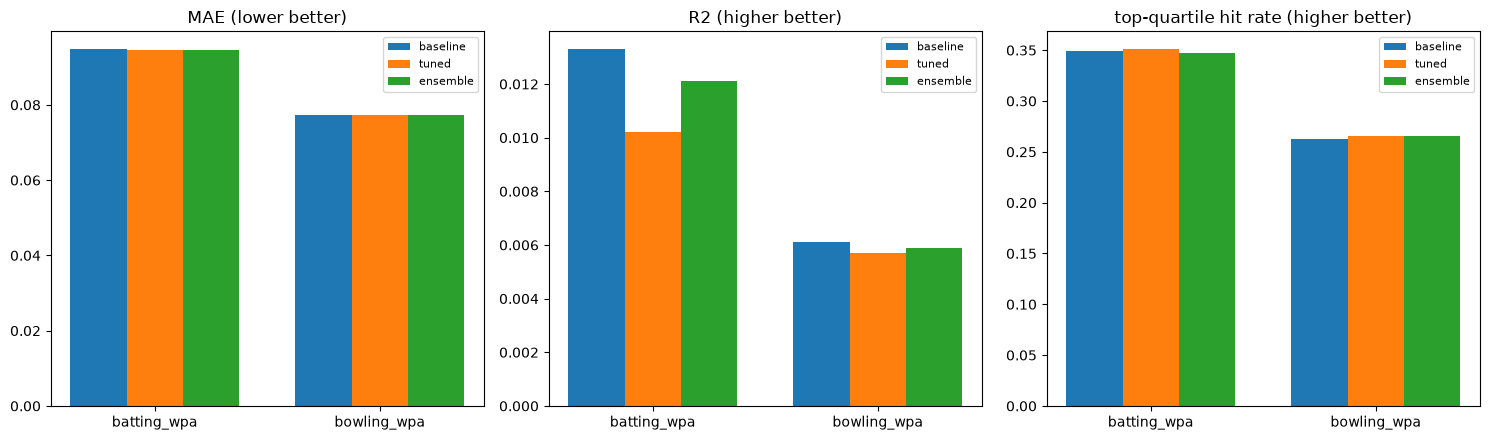

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plot_metrics = [("mae", "MAE (lower better)"), ("r2", "R2 (higher better)"),
                 ("top_quartile_hit_rate_within_match", "top-quartile hit rate (higher better)")]
targets = list(report_a["targets"].keys())
variants = ["baseline", "tuned", "ensemble"]
x = np.arange(len(targets))
width = 0.25
for ax, (metric, title) in zip(axes, plot_metrics):
    for i, variant in enumerate(variants):
        vals = [report_a["targets"][t].get(variant, {}).get(metric) for t in targets]
        ax.bar(x + (i - 1) * width, vals, width, label=variant)
    ax.set_xticks(x); ax.set_xticklabels(targets)
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


**Reading these numbers honestly:** a near-zero R2 is *expected*, not a
bug, per `ALGORITHMS.md`/`VALIDATION_REPORT.md` -- single-match WPA is an
extremely high-variance target. Correlation and top-quartile hit rate are
the metrics that matter for a ranking task; whether tuning/ensembling
actually moves *those* (not just MAE) is the real signal to read above.

## Part B -- MILP selection quality (constraint compliance + score gap)

Same methodology as `model_evaluation_suite.ipynb`'s Part B: for a sample of
real T20I countries, does `select_xi` always respect its constraints
(exactly 11, minimum batting/bowling-capable, keeper), and how much score
does the constrained pick give up vs. an unconstrained (possibly illegal)
top-11 and vs. a random 11 -- repeated for baseline/tuned/ensemble scores so
the MILP step's own value-add is checked for all three, not just the
shipped baseline.

In [5]:
import random as _random

teams_sample = pd.read_sql_query(
    "SELECT DISTINCT team1 AS team FROM matches "
    "WHERE format=? AND gender=? AND team_type='international' "
    "GROUP BY team1 HAVING COUNT(*) >= 20 ORDER BY RANDOM() LIMIT 5",
    conn, params=(FMT, GENDER))["team"].tolist()
print("sample of real countries used for Part B:", teams_sample)

from criiq_models.recommend.train import load_models
from criiq_models.recommend.tune import load_tuned_models
from criiq_models.recommend.ensemble import build_ensemble_models

engines_b = {"baseline": load_models(FMT, GENDER), "tuned": load_tuned_models(FMT, GENDER),
             "ensemble": build_ensemble_models(FMT, GENDER)}
scorers_b = {name: RecommendationScorer(conn, FMT, GENDER, models=models) for name, models in engines_b.items()}

compliance_rows = []
for team in teams_sample:
    for opponent in teams_sample:
        if team == opponent:
            continue
        pool = team_pool(conn, team, FMT, GENDER)
        if len(pool) < 11:
            continue
        for name, scorer in scorers_b.items():
            scored = scorer.score_many(pool, opponent)
            xi = select_xi(scored)
            xi_ids = {p["player_id"] for p in xi["xi"]}
            by_id = {p["player_id"]: p for p in scored}
            bat_capable = sum(1 for pid in xi_ids if batting_capable(by_id[pid]["role_bucket"]))
            bowl_capable = sum(1 for pid in xi_ids if bowling_capable(by_id[pid]["role_bucket"]))
            keepers = sum(1 for pid in xi_ids if by_id[pid].get("is_keeper"))
            pool_keepers = sum(1 for p in scored if p.get("is_keeper"))
            milp_score = sum(by_id[pid]["score"] for pid in xi_ids)
            naive_top11 = sorted(scored, key=lambda p: -p["score"])[:11]
            naive_score = sum(p["score"] for p in naive_top11)
            random_scores = [sum(by_id[pid]["score"] for pid in _random.sample(pool, 11)) for _ in range(100)]
            compliance_rows.append({
                "engine": name, "team": team, "opponent": opponent, "pool_size": len(pool),
                "xi_size_ok": len(xi_ids) == min(11, len(pool)),
                "min_batting_ok": bat_capable >= min(SETTINGS.min_batting_capable, sum(1 for p in scored if batting_capable(p["role_bucket"]))),
                "min_bowling_ok": bowl_capable >= min(SETTINGS.min_bowling_capable, sum(1 for p in scored if bowling_capable(p["role_bucket"]))),
                "keeper_ok": keepers >= min(SETTINGS.min_keepers, pool_keepers),
                "milp_score": milp_score, "naive_top11_score": naive_score,
                "random_mean_score": np.mean(random_scores),
            })

comp_df = pd.DataFrame(compliance_rows)
print(f"{len(comp_df)} (engine, team, opponent) pools checked.\n")
summary_b = comp_df.groupby("engine").agg(
    xi_size_ok=("xi_size_ok", "mean"), min_batting_ok=("min_batting_ok", "mean"),
    min_bowling_ok=("min_bowling_ok", "mean"), keeper_ok=("keeper_ok", "mean"),
    mean_milp_score=("milp_score", "mean"), mean_naive_score=("naive_top11_score", "mean"),
    mean_random_score=("random_mean_score", "mean"))
summary_b[["xi_size_ok", "min_batting_ok", "min_bowling_ok", "keeper_ok"]] = \
    (summary_b[["xi_size_ok", "min_batting_ok", "min_bowling_ok", "keeper_ok"]] * 100).round(1)
summary_b


sample of real countries used for Part B: ['Uganda', 'Ireland', 'Germany', 'South Africa', 'Thailand']


60 (engine, team, opponent) pools checked.



,xi_size_ok,min_batting_ok,min_bowling_ok,keeper_ok,mean_milp_score,mean_naive_score,mean_random_score
engine,,,,,,,
baseline,100.0,100.0,100.0,100.0,147.785,149.265,92.2240
ensemble,100.0,100.0,100.0,100.0,143.790,145.155,89.7110
tuned,100.0,100.0,100.0,100.0,140.715,141.955,89.1124


**Reading this table:** the compliance columns should read 100% for
every engine -- `select_xi`'s constraints don't depend on which model
produced the scores, only on the unchanged MILP formulation. `mean_milp_score`
vs. `mean_random_score` is the value the optimizer adds over guessing;
vs. `mean_naive_score` is the real cost of requiring a legal, balanced side.

## Part C -- the real-world test: overlap with the actually-fielded XI

The centerpiece: on `matches_holdout` (genuinely unseen forward-holdout
matches none of the persisted artifacts trained on, same methodology as
`VALIDATION_REPORT.md` SS11/14), how often does each engine's pick match what
the real coach actually fielded? This is the most direct answer to "which
engine is better, validated against real matches" -- baseline/tuned/ensemble
via the unchanged MILP selector, and `model_ranker` picking its top-11/20
directly with no MILP at all.

In [6]:
report_c = xi_overlap_comparison(conn, FMT, GENDER, limit=HOLDOUT_LIMIT)
summary_c = report_c["summary"]
print(f"{summary_c['n_comparisons']} real team-selections checked.")
print(f"random-11 baseline: {summary_c['random_baseline_mean']:.2f} / 11 "
      f"({100*summary_c['random_baseline_mean']/11:.1f}%)\n")

engine_rows = []
for name in ("baseline", "tuned", "ensemble", "model_ranker"):
    if name in summary_c:
        engine_rows.append({"engine": name, **summary_c[name]})
summary_c_df = pd.DataFrame(engine_rows).set_index("engine")
summary_c_df


40 real team-selections checked.
random-11 baseline: 5.42 / 11 (49.3%)



,mean_overlap_of_11,mean_overlap_pct,mean_pool20_recall,role_balance_violation_rate
engine,,,,
baseline,7.825,71.1,0.952,NaN
tuned,7.725,70.2,0.952,NaN
ensemble,7.775,70.7,0.952,NaN
model_ranker,7.325,66.6,0.927,0.125


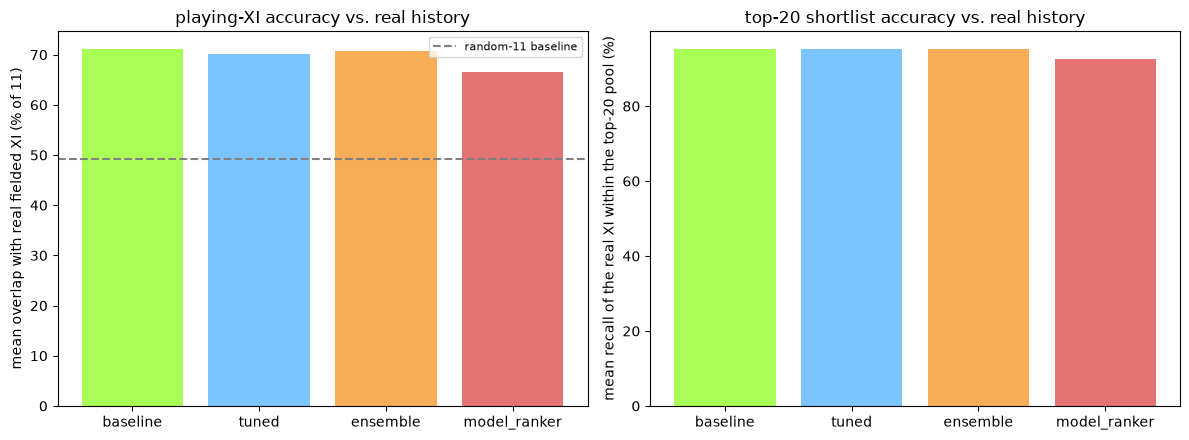

model_ranker role-balance violation rate (picks with fewer than the MILP's own minimum batting/bowling-capable players): 12.5% of its unconstrained top-11 picks -- exactly the failure mode the MILP step exists to prevent.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(summary_c_df.index, summary_c_df["mean_overlap_pct"],
            color=["#AAFF57", "#7cc4ff", "#f6ad55", "#e57373"][:len(summary_c_df)])
axes[0].axhline(100 * summary_c["random_baseline_mean"] / 11, color="gray", linestyle="--",
                label="random-11 baseline")
axes[0].set_ylabel("mean overlap with real fielded XI (% of 11)")
axes[0].set_title("playing-XI accuracy vs. real history")
axes[0].legend(fontsize=8)

axes[1].bar(summary_c_df.index, summary_c_df["mean_pool20_recall"] * 100,
            color=["#AAFF57", "#7cc4ff", "#f6ad55", "#e57373"][:len(summary_c_df)])
axes[1].set_ylabel("mean recall of the real XI within the top-20 pool (%)")
axes[1].set_title("top-20 shortlist accuracy vs. real history")
plt.tight_layout()
plt.show()

if "model_ranker" in summary_c:
    print(f"model_ranker role-balance violation rate (picks with fewer than the MILP's own minimum "
          f"batting/bowling-capable players): {100*summary_c['model_ranker']['role_balance_violation_rate']:.1f}% "
          f"of its unconstrained top-11 picks -- exactly the failure mode the MILP step exists to prevent.")


## Part D -- the ranker's own ranking-quality metrics

`evaluate/rank_backtest.py`'s existing comparison (an *untuned* `LGBMRanker`
vs. the two regressors' combined score, by top-11 hit rate and Spearman
correlation on the same temporal holdout) -- run here for reference,
alongside the *tuned* ranker's own cross-validated numbers from the training
step above.

In [8]:
rank_report = rank_backtest(conn, FMT, GENDER)
print("untuned LGBMRanker vs. regression-based ranking (evaluate/rank_backtest.py):")
print(f"  ranker:              top_11_hit_rate={rank_report.get('ranker', {}).get('top_11_hit_rate')}  "
      f"spearman={rank_report.get('ranker', {}).get('spearman')}")
print(f"  regression baseline: top_11_hit_rate={rank_report.get('regression_baseline', {}).get('top_11_hit_rate')}  "
      f"spearman={rank_report.get('regression_baseline', {}).get('spearman')}")
print()
print("tuned ranker (this notebook's run, recommend/rank_select.py), cross-validated on train-only folds:")
print(f"  tuned_cv_top11_hit_rate={rt.get('tuned_cv_top11_hit_rate')}  "
      f"baseline_cv_top11_hit_rate={rt.get('baseline_cv_top11_hit_rate')}")


untuned LGBMRanker vs. regression-based ranking (evaluate/rank_backtest.py):
  ranker:              top_11_hit_rate=0.574  spearman=0.076
  regression baseline: top_11_hit_rate=0.64  spearman=0.3

tuned ranker (this notebook's run, recommend/rank_select.py), cross-validated on train-only folds:
  tuned_cv_top11_hit_rate=0.564  baseline_cv_top11_hit_rate=0.5573


## Verdict

In [9]:
verdict_rows = []
for name in ("baseline", "tuned", "ensemble", "model_ranker"):
    if name in summary_c:
        verdict_rows.append({
            "engine": name,
            "real_xi_overlap_pct": summary_c[name]["mean_overlap_pct"],
            "top20_recall_pct": round(summary_c[name]["mean_pool20_recall"] * 100, 1),
            "role_balance_violation_pct": round(100 * summary_c[name].get("role_balance_violation_rate", 0.0), 1),
        })
verdict_df = pd.DataFrame(verdict_rows).set_index("engine").sort_values("real_xi_overlap_pct", ascending=False)
print(verdict_df)
print()

winner = verdict_df["real_xi_overlap_pct"].idxmax()
baseline_pct = summary_c.get("baseline", {}).get("mean_overlap_pct")
winner_pct = verdict_df.loc[winner, "real_xi_overlap_pct"]

if winner == "baseline":
    print(f"VERDICT: the existing MILP-fed baseline pipeline still wins on real-match validation "
          f"({winner_pct}% overlap with the actually-fielded XI) -- neither tuning nor ensembling the "
          f"regressors, nor letting a model pick the XI directly, beat it at n_iter={N_ITER}.")
else:
    delta = round(winner_pct - baseline_pct, 1)
    print(f"VERDICT: '{winner}' beat the existing MILP-fed baseline pipeline on real-match validation "
          f"({winner_pct}% vs. baseline's {baseline_pct}% overlap with the actually-fielded XI, "
          f"a {delta:+.1f} point improvement) at n_iter={N_ITER}.")

if "model_ranker" in verdict_df.index and verdict_df.loc["model_ranker", "role_balance_violation_pct"] > 0:
    print(f"\ncaveat: model_ranker's picks were role-imbalanced (fewer than the required minimum "
          f"batting- or bowling-capable players) {verdict_df.loc['model_ranker', 'role_balance_violation_pct']}% "
          f"of the time -- a real, visible cost of dropping the MILP constraint step, not reflected in the "
          f"overlap percentage alone.")


              real_xi_overlap_pct  top20_recall_pct  \
engine                                                
baseline                     71.1              95.2   
ensemble                     70.7              95.2   
tuned                        70.2              95.2   
model_ranker                 66.6              92.7   

              role_balance_violation_pct  
engine                                    
baseline                             0.0  
ensemble                             0.0  
tuned                                0.0  
model_ranker                        12.5  

VERDICT: the existing MILP-fed baseline pipeline still wins on real-match validation (71.1% overlap with the actually-fielded XI) -- neither tuning nor ensembling the regressors, nor letting a model pick the XI directly, beat it at n_iter=4.

caveat: model_ranker's picks were role-imbalanced (fewer than the required minimum batting- or bowling-capable players) 12.5% of the time -- a real, visible cost of dr

**Note on `N_ITER`:** this notebook used a reduced search depth for
runtime. Re-run with a larger `N_ITER` (and `HOLDOUT_LIMIT`) at the top of
the Setup section -- or via the CLI (`tune --n-iter 30`,
`tune-ranker --n-iter 30`, `compare-engines --n-iter 30 --holdout-limit 100`)
-- for a deeper, more conclusive search before treating this verdict as
final.

In [10]:
conn.close()